# Clase 6 — Grandes Modelos de Lenguaje

**Demostración en Python**

En las diapositivas vimos que un LLM es un Transformer decodificador que predice el siguiente token, ajustado después para seguir instrucciones. En este notebook lo vamos a usar de dos formas:

**Parte A — Un modelo abierto en Colab** (gratis, sin clave):

1. Cargar un LLM pequeño, **Qwen2.5-0.5B-Instruct**.
2. Mirar la **distribución del siguiente token** y cómo se tokeniza el texto.
3. **Decodificación**: cómo se convierte una distribución en texto. Greedy, beam search, muestreo, top-k, top-p y temperatura, con la teoría y los experimentos.
4. **Plantillas de chat**: el mismo modelo con y sin su plantilla.

**Parte B — Un modelo grande por la API de OpenAI** (requiere clave):

5. Roles, instrucciones y **few-shot**.
6. **Salidas estructuradas** con Pydantic.
7. **Razonamiento**: cuánto “piensa” el modelo antes de responder.
8. Un **clasificador de sentimiento** de reseñas con LLM, evaluado contra un baseline TF-IDF.


In [49]:
#@title Preparación: librerías y funciones auxiliares
# Instala lo que falte en el mismo Python del notebook (en Colab normalmente solo falta openai).
# Usamos %pip y no !pip: !pip llama al pip de la terminal, que puede no existir o ser de otro Python.
import importlib.util, sys
PAQUETES = {"openai": "openai", "transformers": "transformers", "torch": "torch", "datasets": "datasets",
            "sklearn": "scikit-learn", "matplotlib": "matplotlib", "pydantic": "pydantic"}
faltan = [pip for modulo, pip in PAQUETES.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    print("Instalando:", " ".join(faltan))
    if importlib.util.find_spec("pip") is None:      # algunos entornos (p. ej. creados con uv) no traen pip
        !"{sys.executable}" -m ensurepip
    %pip install -q {" ".join(faltan)}

import openai

import os, time, math, json
from typing import Literal

import numpy as np
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from IPython.display import display, Markdown

%config InlineBackend.figure_formats = ['retina']
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

AZUL, ROJO, VERDE, NARANJO, MORADO, GRIS = "#6c8ebf", "#b85450", "#82b366", "#d79b00", "#9673a6", "#999999"

def ver_token(t):
    """Muestra un token de forma legible: los espacios como · y los saltos de línea como ⏎."""
    return t.replace(" ", "·").replace("\n", "⏎")

def barras(pares, titulo="", color=AZUL, ax=None):
    """Gráfico de barras horizontal de una lista [(token, probabilidad), ...]."""
    ax = ax or plt.subplots(figsize=(6, 0.35 * len(pares) + 0.8))[1]
    etiquetas = [ver_token(t) for t, _ in pares][::-1]
    valores = [p for _, p in pares][::-1]
    ax.barh(etiquetas, valores, color=color)
    for i, v in enumerate(valores):
        ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
    ax.set_xlim(0, 1.1)
    ax.set_title(titulo, fontsize=11)
    return ax

# Parte A — Un modelo abierto en Colab

# 1. Un LLM pequeño en tu computador

Usaremos **[Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct)**, un modelo abierto de Alibaba con unos 500 millones de parámetros: unas 350 veces más chico que GPT-3, pero con la **misma arquitectura** (Transformer decodificador) y entrenado con las mismas etapas que vimos en la teoría (preentrenamiento + instrucciones + preferencias).

Pesa cerca de 1 GB y corre en la CPU de Colab; con GPU (*Entorno de ejecución → Cambiar tipo de entorno*) es más rápido.

### La librería 🤗 Transformers

Para descargar y usar el modelo usamos **[Transformers](https://huggingface.co/docs/transformers)**, la librería de Hugging Face. Es la forma estándar de trabajar con modelos abiertos: BERT, GPT-2, Llama, Qwen, Mistral y miles más se cargan con las mismas tres líneas.

| Pieza | Qué hace |
|---|---|
| **Hub** de Hugging Face | Repositorio público de modelos. `"Qwen/Qwen2.5-0.5B-Instruct"` es el nombre del modelo ahí (organización/modelo). |
| `AutoTokenizer.from_pretrained(nombre)` | Descarga el tokenizador del modelo: convierte texto en *ids* de tokens y de vuelta (`tok.decode`). |
| `AutoModelForCausalLM.from_pretrained(nombre)` | Descarga los pesos y la configuración. *Causal LM* = modelo que predice el siguiente token (un decodificador). *Auto* elige la clase correcta (aquí `Qwen2ForCausalLM`) leyendo la configuración. |
| `modelo(ids).logits` | Una pasada por la red: una puntuación por cada token del vocabulario, en cada posición. |
| `modelo.generate(...)` | El ciclo de decodificación completo (greedy, beam search, muestreo…), que veremos en la sección 3. |

Los modelos son de **PyTorch** (`torch`): por eso movemos el modelo a la CPU o GPU con `.to(dispositivo)` y usamos tensores. La primera vez se descargan del Hub y quedan guardados en caché (`~/.cache/huggingface`).

In [ ]:
MODELO_LOCAL = "Qwen/Qwen2.5-0.5B-Instruct"
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"

tok = AutoTokenizer.from_pretrained(MODELO_LOCAL)
# float32: más preciso que bf16 y en un modelo tan chico (~2 GB) no pesa
modelo = AutoModelForCausalLM.from_pretrained(MODELO_LOCAL, dtype=torch.float32).to(dispositivo)
modelo.eval()

n_param = sum(p.numel() for p in modelo.parameters())
print(f"Parámetros: {n_param / 1e6:.0f} millones   ·   vocabulario: {len(tok):,} tokens   ·   dispositivo: {dispositivo}")

Parámetros: 494 millones   ·   vocabulario: 151,665 tokens   ·   dispositivo: cpu


In [ ]:
entrada = tok("La capital de Chile es", return_tensors="pt").to(dispositivo)
print("input_ids:", entrada.input_ids.tolist())
print("tokens:   ", [tok.decode([i]) for i in entrada.input_ids[0]])

with torch.no_grad():                      # solo inferencia: no hace falta guardar gradientes
    salida = modelo(**entrada)
print("logits:   ", tuple(salida.logits.shape), "= (textos, posiciones, vocabulario)")
print("clase del modelo:", type(modelo).__name__)

input_ids: [[8747, 6722, 409, 33000, 1531]]
tokens:    ['La', ' capital', ' de', ' Chile', ' es']
logits:    (1, 5, 151936) = (textos, posiciones, vocabulario)
clase del modelo: Qwen2ForCausalLM


El tokenizador entrega los *ids* (`return_tensors="pt"` pide un tensor de PyTorch) y el modelo devuelve un tensor de logits con **una fila por posición**: la fila $i$ puntúa cuál token viene después del token $i$. Para predecir lo que sigue al texto miramos la **última** fila, `logits[0, -1]`. Eso es exactamente lo que hace la función de la sección siguiente.

# 2. El modelo predice el siguiente token

Un modelo de lenguaje recibe un texto y entrega una **distribución de probabilidad** sobre todo su vocabulario para el token siguiente: $P(w_n \mid w_1, \dots, w_{n-1})$.

La función `siguiente_token` hace exactamente eso: pasa el texto por el modelo, toma los *logits* de la última posición, los divide por la temperatura $T$ y aplica softmax.

**Antes de ejecutar:** para el texto `"La capital de Chile es"`, ¿qué token esperan en primer lugar? ¿Con qué probabilidad, aproximadamente?

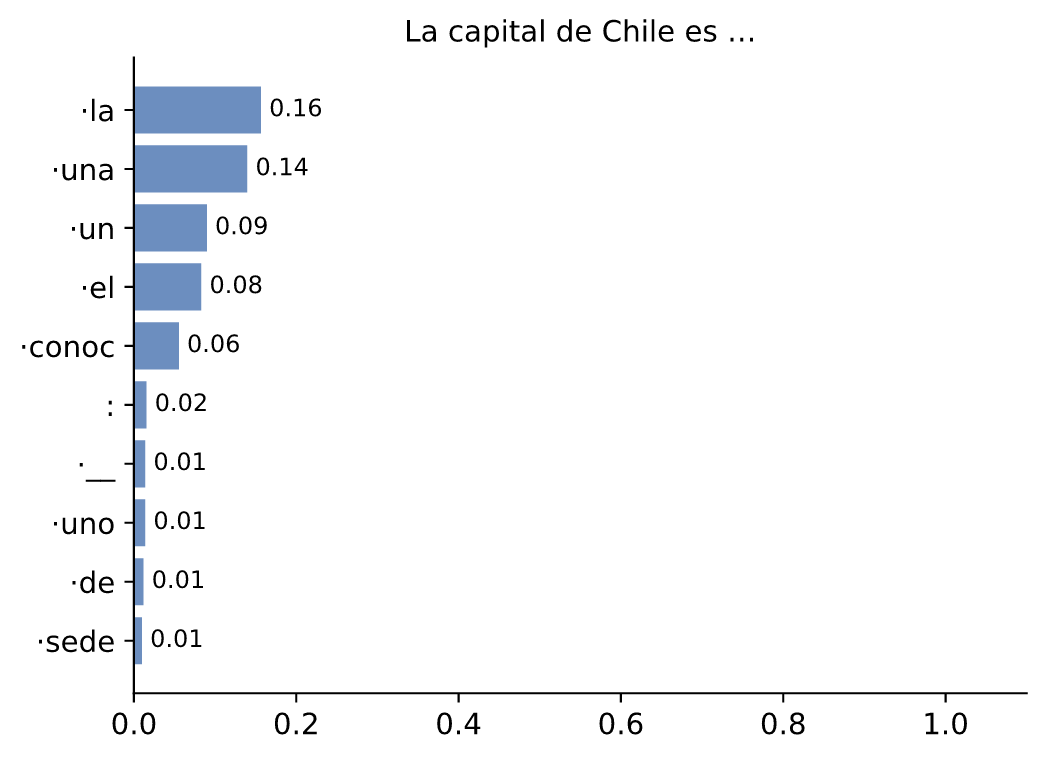

In [51]:
@torch.no_grad()
def distribucion(texto, T=1.0):
    """Probabilidad de cada token del vocabulario como siguiente token de `texto`."""
    ids = tok(texto, return_tensors="pt").input_ids.to(dispositivo)
    logits = modelo(ids).logits[0, -1].float()          # una puntuación por token del vocabulario
    return torch.softmax(logits / T, dim=-1)

def siguiente_token(texto, k=10, T=1.0):
    """Los k tokens más probables después de `texto`, con su probabilidad."""
    top = torch.topk(distribucion(texto, T), k)
    return [(tok.decode([int(i)]), p.item()) for i, p in zip(top.indices, top.values)]

barras(siguiente_token("La capital de Chile es"), "La capital de Chile es …");

Observen que los candidatos empiezan con un espacio (lo mostramos como `·`): el modelo no predice **palabras** sino **tokens**, y el espacio forma parte del token.

Prueben con otros comienzos. ¿Qué pasa con un texto ambiguo, como `"Fui al banco a"`? ¿La distribución es más plana o más marcada?

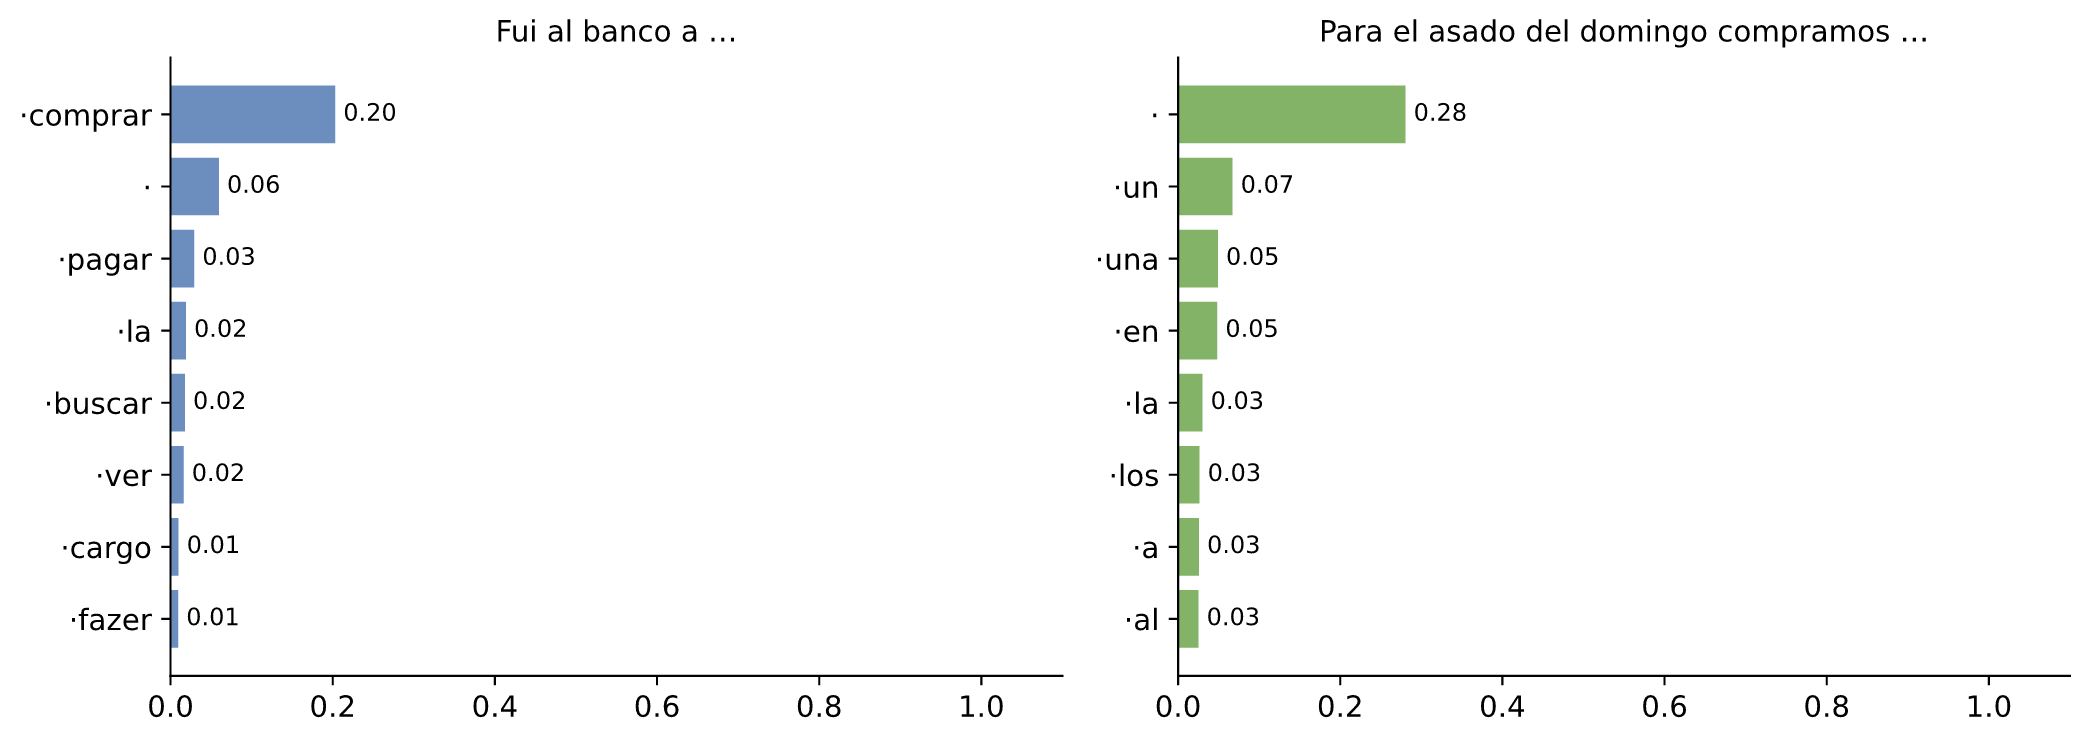

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
barras(siguiente_token("Fui al banco a", k=8), "Fui al banco a …", AZUL, axes[0])
barras(siguiente_token("Para el asado del domingo compramos", k=8), "Para el asado del domingo compramos …", VERDE, axes[1])
plt.tight_layout()

### Tokens, no palabras

El tokenizador de Qwen usa **BPE** (lo vimos en el notebook 1.1). Las palabras frecuentes son un solo token; las raras, técnicas o muy chilenas (“tinca”, “carrete”) se parten en varios. Esto importa: las APIs **cobran por token**, y el largo máximo del contexto también se mide en tokens.

In [53]:
for frase in ["La capital de Chile es Santiago.",
              "Me tinca que el carrete de anoche estuvo bacán",
              "El tribunal declaró la inconstitucionalidad del procedimiento"]:
    piezas = [ver_token(tok.decode([i])) for i in tok(frase).input_ids]
    print(f"{len(piezas):>2} tokens  {len(frase.split()):>2} palabras  |  " + " | ".join(piezas))

 7 tokens   6 palabras  |  La | ·capital | ·de | ·Chile | ·es | ·Santiago | .
14 tokens   9 palabras  |  Me | ·tin | ca | ·que | ·el | ·car | rete | ·de | ·ano | che | ·est | uvo | ·bac | án
14 tokens   7 palabras  |  El | ·tribunal | ·declar | ó | ·la | ·in | const | it | uc | ional | idad | ·del | ·proced | imiento


# 3. Decodificación: de probabilidades a texto

El modelo solo entrega una **distribución de probabilidad** sobre el vocabulario para el siguiente token. Para generar texto hay que repetir un ciclo: calcular la distribución, **elegir** un token, agregarlo al contexto y volver a empezar. La regla para elegir es la **estrategia de decodificación**, y cambia mucho el resultado.

Veremos cuatro ideas: **greedy**, **beam search**, **muestreo** (con top-k y top-p) y **temperatura**.

### Greedy: siempre el más probable

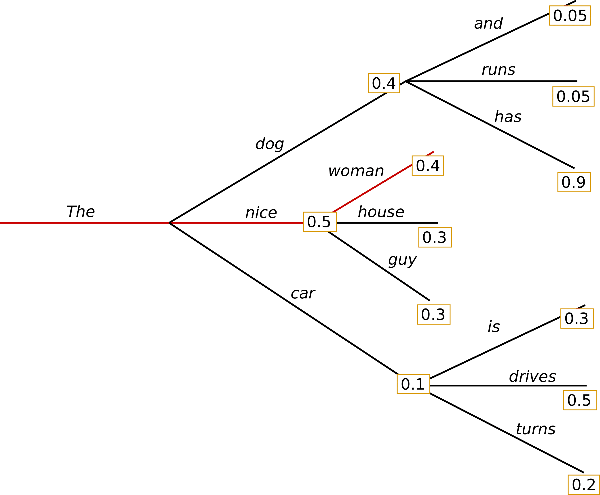

En cada paso elige el token de mayor probabilidad. En el árbol: después de *The* elige *nice* (0,5) y luego *woman* (0,4), con probabilidad total 0,5 × 0,4 = **0,20**. Pero *The dog has* tenía 0,4 × 0,9 = **0,36**: greedy no la ve, porque estaba escondida detrás de un token menos probable (*dog*). Además es determinista y tiende a repetirse.

Escribamos el ciclo a mano.

In [54]:
@torch.no_grad()
def greedy_a_mano(texto, n_tokens=12):
    ids = tok(texto, return_tensors="pt").input_ids.to(dispositivo)
    for _ in range(n_tokens):
        probs = torch.softmax(modelo(ids).logits[0, -1].float(), dim=-1)
        p, i = probs.max(dim=-1)                       # el token más probable
        print(f"{ver_token(tok.decode([int(i)])):<14} p = {p:.2f}")
        ids = torch.cat([ids, i.view(1, 1)], dim=1)    # se agrega al contexto
    return tok.decode(ids[0])

print("\n→", greedy_a_mano("Los tres ingredientes de una buena empanada de pino son"))

:              p = 0.51
·el            p = 0.17
·pan           p = 0.23
,              p = 0.70
·el            p = 0.69
·p             p = 0.30
ino            p = 0.71
·y             p = 0.85
·el            p = 0.52
·ace           p = 0.07
ite            p = 0.94
.              p = 0.58

→ Los tres ingredientes de una buena empanada de pino son: el pan, el pino y el aceite.


### El árbol que greedy no mira

Greedy sigue **una sola rama**. Dibujemos las **2 opciones más probables en cada paso** para ver qué deja de lado. La probabilidad de una secuencia es el **producto** de las probabilidades de sus tokens. En **rojo**, el camino de greedy; en **verde**, la secuencia más probable del árbol (cuando es otra).

**Antes de ejecutar:** ¿encontrará greedy la secuencia más probable?

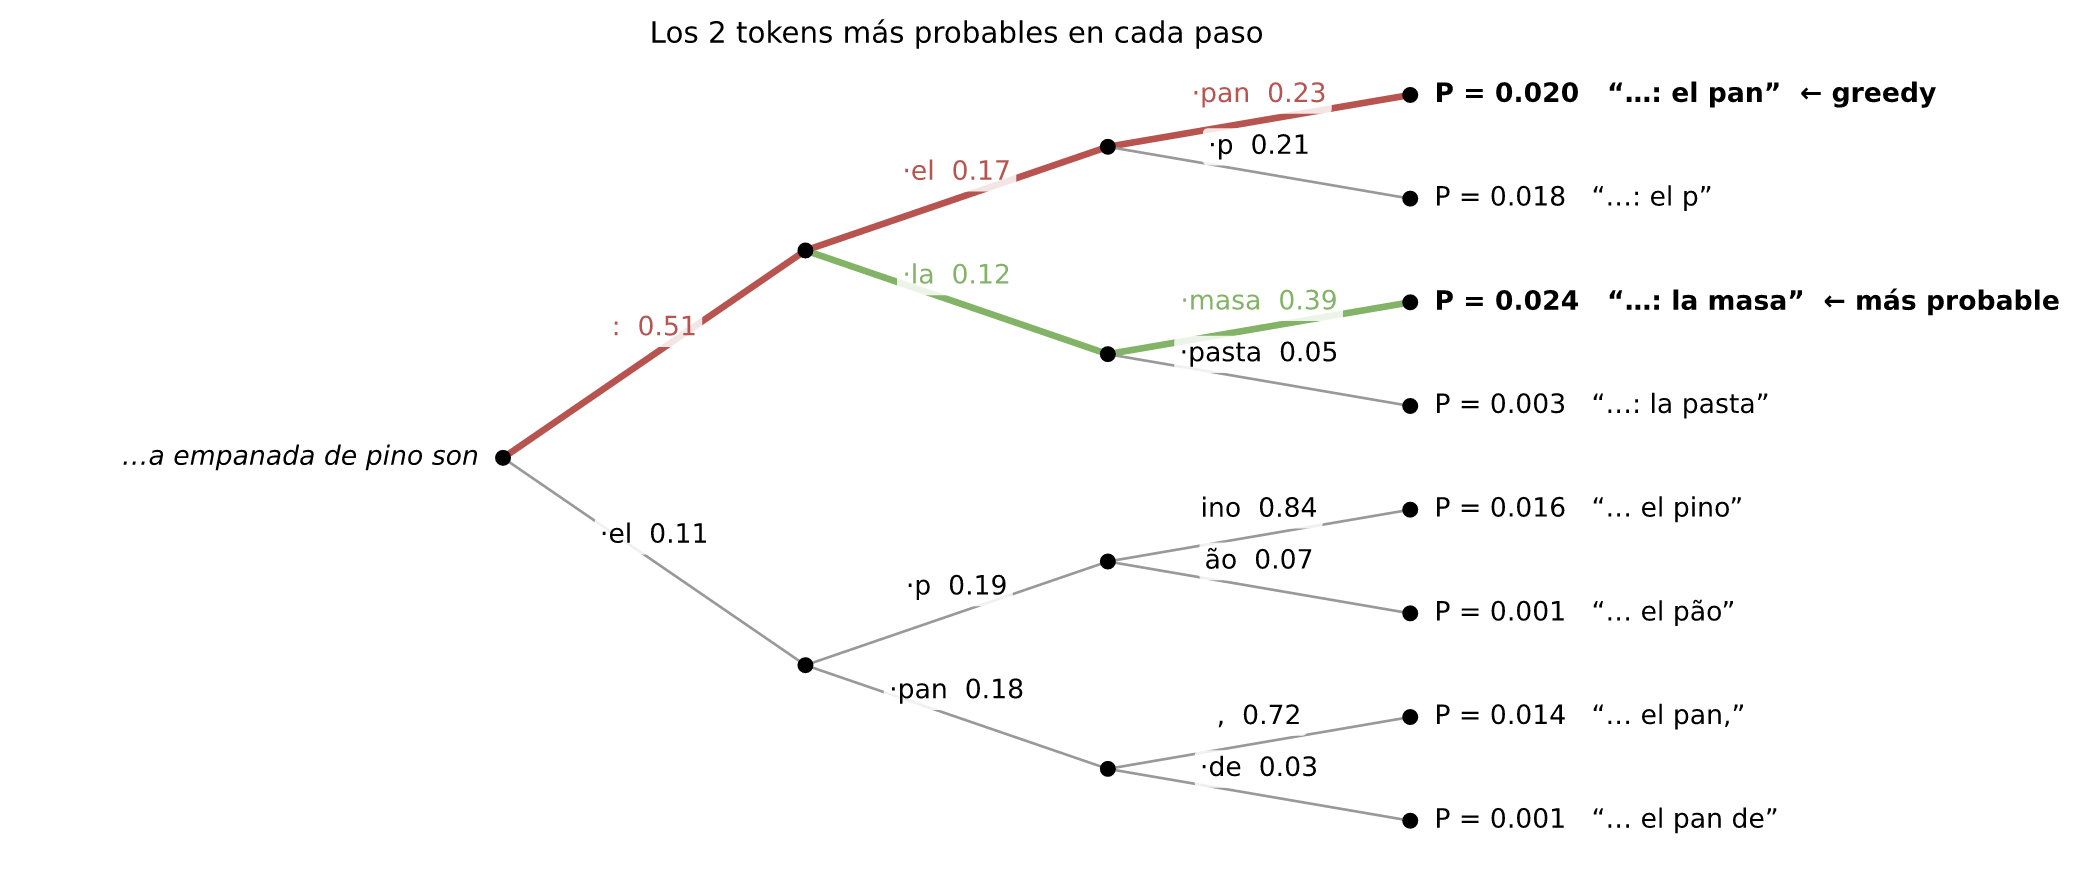

Greedy:        “…: el pan”   P = 0.020
Más probable:  “…: la masa”   P = 0.024
→ Greedy no encontró la secuencia más probable del árbol.


In [55]:
@torch.no_grad()
def arbol_decision(texto, profundidad=3, k=2):
    """Dibuja el árbol con los k tokens más probables en cada paso.
    Rojo: el camino que sigue greedy. Verde: la secuencia más probable del árbol."""
    def expandir(ids, nivel):
        if nivel == profundidad:
            return []
        probs = torch.softmax(modelo(ids).logits[0, -1].float(), dim=-1)
        top = torch.topk(probs, k)
        hijos = []
        for p, i in zip(top.values, top.indices):
            nuevos = torch.cat([ids, i.view(1, 1)], dim=1)
            hijos.append({"token": tok.decode([int(i)]), "p": p.item(), "hijos": expandir(nuevos, nivel + 1)})
        return hijos

    raiz = {"token": "", "p": 1.0, "hijos": expandir(tok(texto, return_tensors="pt").input_ids.to(dispositivo), 0)}

    # posiciones: hojas espaciadas en y; cada nodo interno al medio de sus hijos
    hojas = []
    def ubicar(nodo, x, camino, p_total, frase=""):
        nodo["x"], nodo["camino"], nodo["p_total"], nodo["frase"] = x, camino, p_total, frase + nodo["token"]
        if not nodo["hijos"]:
            nodo["y"] = -len(hojas); hojas.append(nodo)
        else:
            for j, h in enumerate(nodo["hijos"]):
                ubicar(h, x + 1, camino + (j,), p_total * h["p"], nodo["frase"])
            nodo["y"] = np.mean([h["y"] for h in nodo["hijos"]])
    ubicar(raiz, 0, (), 1.0)

    greedy = (0,) * profundidad                                    # siempre el primero (el más probable)
    mejor = max(hojas, key=lambda h: h["p_total"])["camino"]

    fig, ax = plt.subplots(figsize=(3.2 * profundidad + 3, 0.55 * len(hojas) + 1))
    def dibujar(nodo):
        for h in nodo["hijos"]:
            en_greedy, en_mejor = h["camino"] == greedy[:len(h["camino"])], h["camino"] == mejor[:len(h["camino"])]
            color = ROJO if en_greedy else (VERDE if en_mejor else GRIS)
            ax.plot([nodo["x"], h["x"]], [nodo["y"], h["y"]], color=color, lw=2.5 if (en_greedy or en_mejor) else 1, zorder=1)
            ax.text((nodo["x"] + h["x"]) / 2, (nodo["y"] + h["y"]) / 2 + 0.12,
                    f"{ver_token(h['token'])}  {h['p']:.2f}", ha="center", va="bottom", fontsize=10,
                    color=color if (en_greedy or en_mejor) else "black",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85), zorder=3)
            dibujar(h)
        ax.scatter([nodo["x"]], [nodo["y"]], s=25, color="black", zorder=2)
    dibujar(raiz)
    for h in hojas:
        marca = "  ← greedy" if h["camino"] == greedy else ""
        marca += "  ← más probable" if h["camino"] == mejor else ""
        ax.text(h["x"] + 0.08, h["y"], f"P = {h['p_total']:.3f}   “…{h['frase']}”{marca}", va="center", fontsize=10,
                fontweight="bold" if marca else "normal")
    ax.text(-0.08, raiz["y"], "…" + texto[-22:], ha="right", va="center", fontsize=10, style="italic")
    ax.set_xlim(-1.6, profundidad + 1.6); ax.axis("off")
    ax.set_title(f"Los {k} tokens más probables en cada paso", fontsize=11)
    plt.show()

    por_camino = {h["camino"]: h for h in hojas}
    g, m = por_camino[greedy], por_camino[mejor]
    print(f"Greedy:        “…{g['frase']}”   P = {g['p_total']:.3f}")
    print(f"Más probable:  “…{m['frase']}”   P = {m['p_total']:.3f}")
    if mejor != greedy:
        print("→ Greedy no encontró la secuencia más probable del árbol.")

arbol_decision("Los tres ingredientes de una buena empanada de pino son", profundidad=3)

Pasa lo mismo que en la figura de arriba. Greedy elige “:” y luego “el” porque eran los más probables **en ese paso**, y termina en “: el pan” (P ≈ 0,020). Por la rama de “la”, menos probable al principio (0,12 contra 0,17), se llega a “: la masa” (P ≈ 0,024), porque “masa” tiene probabilidad 0,39 después de “la”.

Prueben con otros textos y con `profundidad=4`. Ojo: el árbol crece como $2^{\text{profundidad}}$, así que cada nivel duplica las llamadas al modelo. Por eso nadie explora el árbol completo: **beam search** se queda solo con las mejores ramas en cada paso.

### Beam search: varias hipótesis a la vez

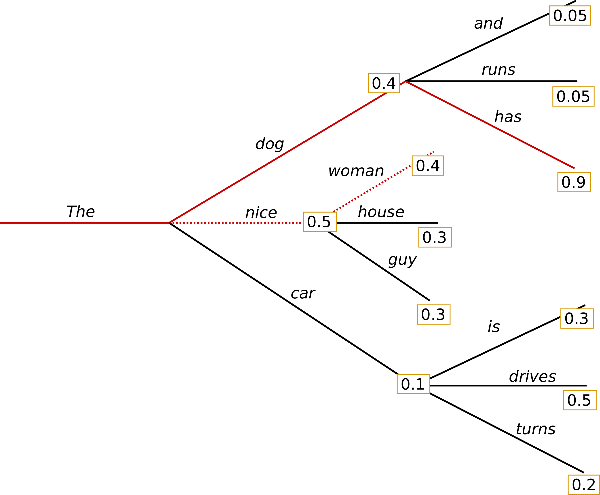

Beam search mantiene las **k mejores secuencias parciales** (los *beams*) en cada paso y, al final, elige la de mayor probabilidad total. Con k = 2 encuentra *The dog has* (0,36). Sigue siendo determinista y se usa sobre todo en traducción y resumen.

Escribámoslo a mano, igual que greedy. En cada paso:

1. **Extender:** a cada beam se le agregan sus mejores tokens siguientes. Con 2 beams y 2 tokens por beam hay 4 candidatos.
2. **Puntuar:** la log-probabilidad de un candidato es la del beam más la del token nuevo. Sumamos logaritmos en vez de multiplicar probabilidades porque los productos de muchas probabilidades se vuelven diminutos.
3. **Podar:** de todos los candidatos sobreviven solo los `n_beams` con mayor log-probabilidad. El resto se descarta para siempre.

**Antes de ejecutar:** con 2 beams y 3 tokens, ¿qué secuencia del árbol debería encontrar beam search?

*Figuras de esta sección: Hugging Face, “How to generate text”.*

In [ ]:
@torch.no_grad()
def beam_a_mano(texto, n_beams=2, n_tokens=3):
    prompt = tok(texto, return_tensors="pt").input_ids.to(dispositivo)
    beams = [(prompt, 0.0)]                                   # (tokens, log P acumulada)
    for paso in range(1, n_tokens + 1):
        # 1) extender: cada beam con sus n_beams tokens más probables
        candidatos = []
        for ids, lp in beams:
            logp = torch.log_softmax(modelo(ids).logits[0, -1].float(), dim=-1)
            top = torch.topk(logp, n_beams)
            for lp_token, i in zip(top.values, top.indices):
                # 2) puntuar: log P(beam + token) = log P(beam) + log P(token | beam)
                candidatos.append((torch.cat([ids, i.view(1, 1)], dim=1), lp + lp_token.item()))
        # 3) podar: sobreviven los n_beams candidatos con mayor log P
        candidatos.sort(key=lambda c: c[1], reverse=True)
        beams = candidatos[:n_beams]
        print(f"Paso {paso}")
        for k, (ids, lp) in enumerate(candidatos):
            marca = "✓ sigue" if k < n_beams else "✗ fuera"
            print(f"   {marca}   P = {math.exp(lp):.3f}   “…{tok.decode(ids[0, prompt.shape[1]:])}”")
    return tok.decode(beams[0][0][0, prompt.shape[1]:])   # el mejor beam

texto = "Los tres ingredientes de una buena empanada de pino son"
print("\n→ Mejor secuencia:", beam_a_mano(texto, n_beams=2, n_tokens=3))

Paso 1
   ✓ sigue   P = 0.514   “…:”
   ✓ sigue   P = 0.105   “… el”
Paso 2
   ✓ sigue   P = 0.087   “…: el”
   ✓ sigue   P = 0.061   “…: la”
   ✗ fuera   P = 0.020   “… el p”
   ✗ fuera   P = 0.019   “… el pan”
Paso 3
   ✓ sigue   P = 0.024   “…: la masa”
   ✓ sigue   P = 0.020   “…: el pan”
   ✗ fuera   P = 0.018   “…: el p”
   ✗ fuera   P = 0.003   “…: la pasta”

→ Mejor secuencia: : la masa


En el paso 1 sobreviven “:” y “ el”. En el paso 2, las dos mejores extensiones salen de “:” (“: el” y “: la”) y la rama “ el” queda fuera. En el paso 3, “: la masa” (0,024) supera a “: el pan” (0,020). Greedy solo siguió “: el” y nunca vio esa opción; beam search la mantuvo viva porque guardó un segundo beam. Nuestra versión simplifica dos cosas que `generate` sí hace: detener los beams que llegan al token de fin de texto y, opcionalmente, penalizar o premiar el largo (`length_penalty`).

### Beam search con `generate`

En la práctica no lo escribimos a mano: basta pasar `num_beams` a `generate`. Para comparar los métodos con justicia, la función `con_logprob` genera con cada configuración y después calcula la log-probabilidad **exacta** de lo generado. Paso a paso:

| Código | Qué hace |
|---|---|
| `tok(texto, return_tensors="pt")` | Tokeniza el prompt. `entrada.input_ids` tiene forma (1, n): n tokens del prompt. |
| `modelo.generate(**entrada, max_new_tokens=..., **params)` | Genera hasta `max_new_tokens` tokens con la estrategia de `params`: `do_sample=False` (determinista), `num_beams=2` (beam search con 2 beams), etc. Devuelve **prompt + tokens nuevos**. |
| `pad_token_id=tok.eos_token_id` | Qwen no define un token de relleno; usamos el de fin de texto para evitar una advertencia. |
| `seq[0, n:]` | Los tokens nuevos: todo lo que viene después del prompt. |
| `modelo(seq).logits[0, :-1]` | **Una sola pasada** por la secuencia completa. La fila i es la distribución del token i + 1, así que la última fila sobra (predice lo que vendría después del final). |
| `log_softmax(...)` | Convierte logits en log-probabilidades. |
| `.gather(1, nuevos[:, None])` | En cada fila, toma la log-probabilidad del token que efectivamente se eligió. |
| `.sum()` | log P(continuación) = suma de las log-probabilidades de sus tokens. |

¿Por qué recalcular en vez de usar lo que reporta `generate`? Porque `generate` solo informa un puntaje en beam search, y además dividido por el largo. Recalculando, los tres métodos se miden con la misma vara.

Ahora la comparación, con 3 tokens (como el árbol) y con 15. Con muchos tokens la probabilidad es diminuta, así que miramos su logaritmo: más cerca de 0 = más probable.

In [ ]:
@torch.no_grad()
def con_logprob(texto, max_new_tokens=15, **params):
    """Genera con la estrategia `params` y devuelve (continuación, log P de la continuación)."""
    entrada = tok(texto, return_tensors="pt").to(dispositivo)
    n = entrada.input_ids.shape[1]                                   # tokens del prompt
    seq = modelo.generate(**entrada, max_new_tokens=max_new_tokens,
                          pad_token_id=tok.eos_token_id, **params)   # prompt + tokens nuevos
    nuevos = seq[0, n:]
    # una pasada por la secuencia completa: la fila i es la distribución del token i + 1
    logp = torch.log_softmax(modelo(seq).logits[0, :-1].float(), dim=-1)
    # log-probabilidad de cada token nuevo (filas n-1 en adelante), sumadas
    total = logp[n - 1:].gather(1, nuevos[:, None]).sum().item()
    return tok.decode(nuevos, skip_special_tokens=True).strip(), total

# Qwen trae por defecto una penalización por repetición; la apagamos para comparar con el árbol
metodos = {"Greedy":               dict(do_sample=False, repetition_penalty=1.0),
           "Beam search, 2 beams": dict(do_sample=False, repetition_penalty=1.0, num_beams=2),
           "Beam search, 4 beams": dict(do_sample=False, repetition_penalty=1.0, num_beams=4)}
for n_tokens in [3, 15]:
    print(f"── {n_tokens} tokens")
    for nombre, params in metodos.items():
        s, lp = con_logprob(texto, max_new_tokens=n_tokens, **params)
        p = math.exp(lp)
        print(f"{nombre:<22} P = {p:.3f}   log P = {lp:6.2f}   →  “…{s}”" if p >= 0.001 else
              f"{nombre:<22} P = {p:.0e}   log P = {lp:6.2f}   →  “…{s}”")

── 3 tokens
Greedy                 P = 0.020   log P =  -3.91   →  “…: el pan”
Beam search, 2 beams   P = 0.024   log P =  -3.74   →  “…: la masa”
Beam search, 4 beams   P = 0.024   log P =  -3.74   →  “…: la masa”
── 15 tokens
Greedy                 P = 1e-06   log P = -13.62   →  “…: el pan, el pino y el aceite. El pino”
Beam search, 2 beams   P = 1e-06   log P = -13.62   →  “…: el pan, el pino y el aceite. El pino”
Beam search, 4 beams   P = 3e-06   log P = -12.73   →  “…: el pino, el azúcar y el aceite de ol”


- Con **3 tokens**, beam search encuentra “: la masa”, la rama verde del árbol que greedy se perdió.
- Con **15 tokens**, 2 beams ya no alcanzan para salir del camino de greedy, pero con 4 beams beam search encuentra una secuencia más probable.
- Ninguna es la receta: el pino no lleva azúcar ni aceite de oliva. Beam search busca la frase **más probable** para el modelo, no la **verdadera**. Y en generación abierta, el texto más probable suele ser genérico o repetitivo. Por eso los asistentes **muestrean**.

### Muestreo, top-k y top-p

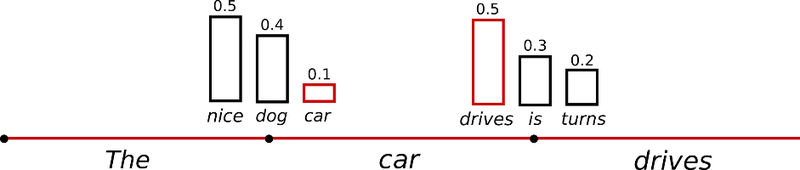

- **Muestreo puro:** sortear el siguiente token según su probabilidad. Ya no es determinista, pero de vez en cuando elige un token absurdo (en la figura, *car* con 0,1).
- **Top-k** (Fan et al., 2018): sortear solo entre los k tokens más probables.
- **Top-p o muestreo de núcleo** (Holtzman et al., 2020): sortear en el grupo más chico de tokens cuya probabilidad suma al menos p (por ejemplo 0,9). El tamaño del grupo se adapta: es chico si el modelo está seguro y grande si no.

### Temperatura

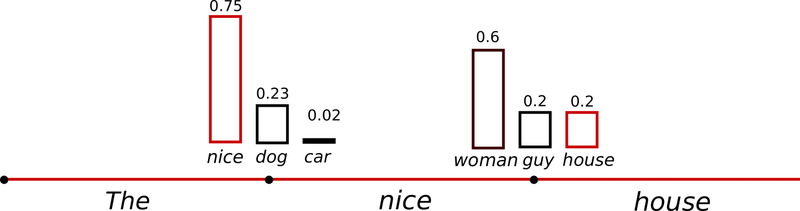

Antes del softmax, los logits $z_i$ se dividen por una temperatura $T$:

$$p_i = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

En la figura, con $T$ baja *nice* pasa de 0,5 a 0,75: el modelo se vuelve más seguro de su primera opción.

**Antes de ejecutar:** con $T = 0{,}5$, ¿la barra más alta crece o se achica? ¿Y con $T = 2$?

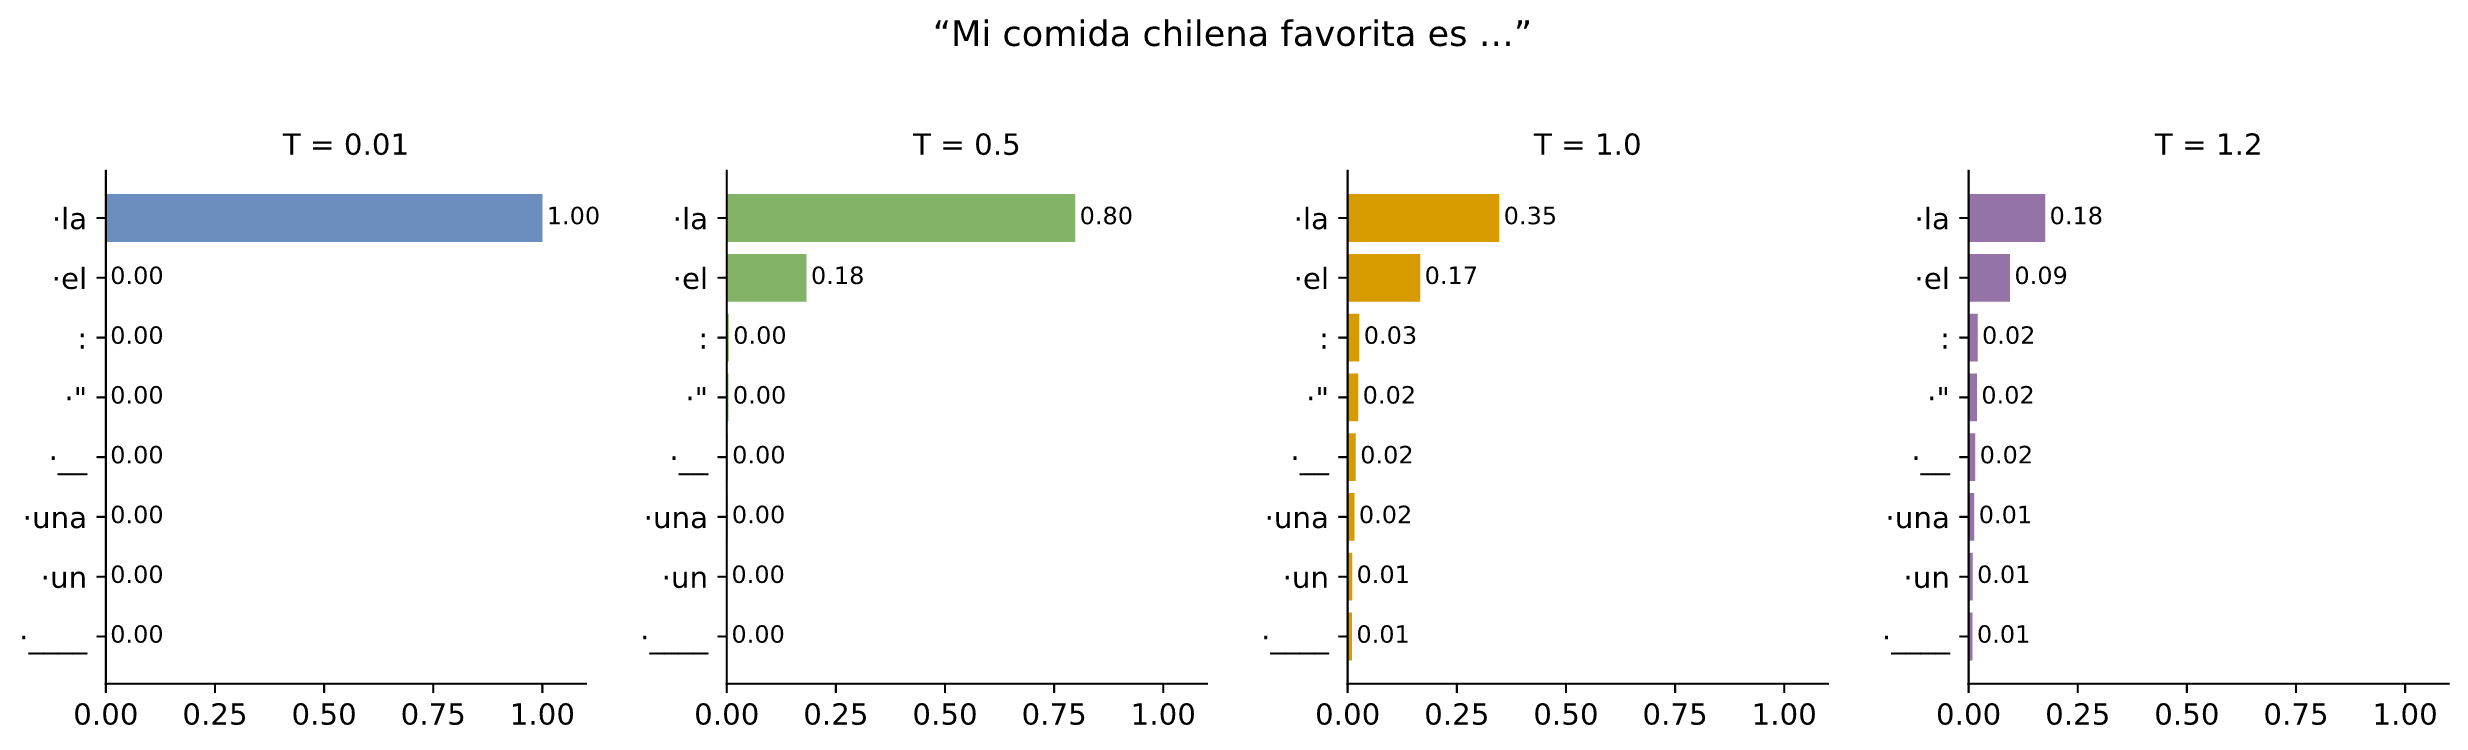

In [60]:
texto = "Mi comida chilena favorita es"
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=False)
top_ids = torch.topk(distribucion(texto), 8).indices          # los mismos 8 tokens en los cuatro gráficos
for ax, T, color in zip(axes, [0.01, 0.5, 1.0, 1.2], [AZUL, VERDE, NARANJO, MORADO]):
    probs = distribucion(texto, T)[top_ids]
    barras([(tok.decode([int(i)]), p.item()) for i, p in zip(top_ids, probs)], f"T = {T}", color, ax)
fig.suptitle(f"“{texto} …”", y=1.02)
plt.tight_layout()

- Con $T < 1$ la distribución se vuelve más **marcada**: el primer token concentra casi toda la probabilidad.
- Con $T > 1$ se **aplana**: tokens poco probables ganan opciones.
- Cuando $T \to 0$ el muestreo equivale a greedy.

### Todo junto con `generate`

En la práctica no escribimos el ciclo a mano: `model.generate` implementa todas las estrategias. Generemos tres veces con cada configuración.

**Antes de ejecutar:** ¿cuál de las configuraciones dará tres textos idénticos?

In [58]:
@torch.no_grad()
def generar(texto, n=3, max_new_tokens=25, **params):
    ids = tok(texto, return_tensors="pt").to(dispositivo)
    salidas = []
    for _ in range(n):
        out = modelo.generate(**ids, max_new_tokens=max_new_tokens, pad_token_id=tok.eos_token_id, **params)
        salidas.append(tok.decode(out[0, ids.input_ids.shape[1]:], skip_special_tokens=True).strip())
    return salidas

@torch.no_grad()
def muestras(texto, n=3, max_new_tokens=25, **params):
    """Genera n continuaciones y, para cada una, la probabilidad media (con T = 1) de los tokens elegidos."""
    ids = tok(texto, return_tensors="pt").to(dispositivo)
    largo = ids.input_ids.shape[1]
    salida = []
    for _ in range(n):
        seq = modelo.generate(**ids, max_new_tokens=max_new_tokens, pad_token_id=tok.eos_token_id, **params)
        logp = torch.log_softmax(modelo(seq).logits[0, :-1].float(), dim=-1)
        elegidos = [logp[i, seq[0, i + 1]].item() for i in range(largo - 1, seq.shape[1] - 1)]
        salida.append((tok.decode(seq[0, largo:], skip_special_tokens=True).strip(), math.exp(np.mean(elegidos))))
    return salida

texto = "Había una vez, en un cerro de Valparaíso,"
# Fijamos todos los parámetros: Qwen trae por defecto top_k=20, top_p=0,8 y una penalización por repetición
configs = {
    "Greedy": (dict(do_sample=False, repetition_penalty=1.0),
               "Elige siempre el token más probable: no hay azar."),
    "Muestreo T=0,7 · top-p=0,9": (dict(do_sample=True, temperature=0.7, top_p=0.9, top_k=0, repetition_penalty=1.0),
               "Sortea solo entre los tokens que suman el 90 % de la probabilidad, con la distribución algo más marcada (T < 1)."),
    "Muestreo T=1,5 (sin top-p)": (dict(do_sample=True, temperature=1.5, top_p=1.0, top_k=0, repetition_penalty=1.0),
               "Sortea entre todo el vocabulario, con la distribución aplanada (T > 1): los tokens raros ganan opciones."),
}
torch.manual_seed(0)
for nombre, (params, descripcion) in configs.items():
    print(f"── {nombre}")
    print(f"   {descripcion}")
    print(f"   {params}")
    res = muestras(texto, **params)
    for s, _ in res:
        print("  ·", s.replace("\n", " "))
    distintos = len({s for s, _ in res})
    pm = np.mean([p for _, p in res])
    print(f"   → {distintos} de {len(res)} textos distintos · probabilidad media de cada token elegido: "
          + (f"{pm:.2f}" if pm >= 0.01 else f"{pm:.0e}") + "\n")

── Greedy
   Elige siempre el token más probable: no hay azar.
   {'do_sample': False, 'repetition_penalty': 1.0}
  · Chile, un hombre llamado José. Era un hombre de 30 años, con una voz suave y un ro
  · Chile, un hombre llamado José. Era un hombre de 30 años, con una voz suave y un ro
  · Chile, un hombre llamado José. Era un hombre de 30 años, con una voz suave y un ro
   → 1 de 3 textos distintos · probabilidad media de cada token elegido: 0.25

── Muestreo T=0,7 · top-p=0,9
   Sortea solo entre los tokens que suman el 90 % de la probabilidad, con la distribución algo más marcada (T < 1).
   {'do_sample': True, 'temperature': 0.7, 'top_p': 0.9, 'top_k': 0, 'repetition_penalty': 1.0}
  · Chile, un chico llamado León. León era un muy buen matemático, pero estaba tan lejos
  · se encontraba un hombre que se llamaba Paul. Se había enamorado de una niña que se llamaba Rosita
  · un joven de 25 años, que había viajado por las costas de Chile. Durante un viaje
   → 3 de 3 textos distintos

La última línea de cada bloque resume la diferencia. La *probabilidad media* es la media geométrica de la probabilidad que el modelo (con T = 1) le daba a cada token elegido.

- **Greedy:** 1 texto distinto de 3, porque no hay azar. Sus tokens son los más probables (≈ 0,25 en promedio).
- **T = 0,7 y top-p = 0,9:** 3 historias distintas y coherentes. Sus tokens son algo menos probables (≈ 0,18): el azar abre otros caminos, pero el recorte de top-p deja fuera las opciones absurdas.
- **T = 1,5 sin recorte:** 3 textos distintos pero sin sentido, con palabras de otros idiomas. La probabilidad media cae a ≈ 0,0003: el modelo elige tokens que casi había descartado, y cada error hace más probable el siguiente. Es el problema del muestreo puro.

### ¿Qué configuración usar?

| Tarea | Temperatura | Por qué |
|---|---|---|
| Clasificación, extracción | 0 | Queremos la misma respuesta cada vez |
| Preguntas factuales | 0 – 0,3 | Precisión antes que variedad |
| Resumen, redacción | 0,5 – 0,8 | Texto natural sin perder el foco |
| Ideas, escritura creativa | 0,8 – 1,2 | Variedad y sorpresa |

Son valores orientativos, no reglas. Aun con temperatura 0, las APIs no garantizan respuestas idénticas. Y algunos **modelos de razonamiento** (como GPT-5, que usaremos en la Parte B) no permiten cambiar la temperatura: ahí se controla el *esfuerzo de razonamiento*.

# 4. Plantillas de chat: el mismo modelo, con y sin plantilla

Qwen2.5-0.5B-**Instruct** fue ajustado con conversaciones en un formato especial. `apply_chat_template` convierte una lista de mensajes con roles en ese texto.

In [61]:
mensajes = [
    {"role": "system", "content": "Eres un asistente breve y preciso."},
    {"role": "user", "content": "¿Cuál es la capital de Chile?"},
]
con_plantilla = tok.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
print(con_plantilla)

<|im_start|>system
Eres un asistente breve y preciso.<|im_end|>
<|im_start|>user
¿Cuál es la capital de Chile?<|im_end|>
<|im_start|>assistant



Esos `<|im_start|>` y `<|im_end|>` son **tokens especiales** que el modelo aprendió durante el ajuste con instrucciones.

**Antes de ejecutar:** si le damos al modelo solo la pregunta, sin plantilla, ¿responderá o seguirá escribiendo como si fuera el comienzo de un documento?

In [62]:
pregunta = "¿Cuál es la capital de Chile?"
print("── Sin plantilla (como un modelo base):")
print(generar(pregunta, n=1, max_new_tokens=40, do_sample=False)[0])
print("\n── Con plantilla de chat:")
print(generar(con_plantilla, n=1, max_new_tokens=40, do_sample=False)[0])

── Sin plantilla (como un modelo base):
La capital de Chile es Santiago. Es una ciudad ubicada en el norte del país, en la región de Antofagasta. Aquí te presento algunos datos importantes sobre Santiago:

1

── Con plantilla de chat:
La capital de Chile es Santiago.


Sin plantilla, el modelo trata la pregunta como el inicio de un texto y lo **continúa**: a veces con más preguntas, a veces con una respuesta larga que no se detiene, y que puede incluir datos inventados (¡alucinaciones!). Con la plantilla, **responde** y se detiene en `<|im_end|>`. Las APIs comerciales aplican la plantilla por nosotros: solo enviamos la lista de mensajes.

# Parte B — Un modelo grande por API

# 5. La API de OpenAI

Un modelo de 0,5 mil millones de parámetros sirve para entender el mecanismo, pero se equivoca mucho. Para tareas reales usaremos un modelo grande a través de la API de OpenAI.

**Configuración (una vez):**

1. Crear una clave en [platform.openai.com/api-keys](https://platform.openai.com/api-keys).
2. En Colab, abrir el panel 🔑 **Secretos**, crear un secreto llamado `OPENAI_API_KEY` con la clave y darle acceso al notebook.

Nunca escriban la clave directamente en una celda: el notebook se comparte y la clave quedaría expuesta.

Usamos `gpt-5-nano`, el modelo más barato de la familia GPT-5. Pueden cambiar `MODELO` por otro modelo disponible en su cuenta (por ejemplo, `gpt-5-mini`).

In [ ]:
from openai import OpenAI
from getpass import getpass

try:                                     # Colab: secreto OPENAI_API_KEY
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
except Exception:
    if not os.environ.get("OPENAI_API_KEY"):
        os.environ["OPENAI_API_KEY"] = getpass("Clave de OpenAI: ")

client = OpenAI()                        # lee OPENAI_API_KEY del entorno
MODELO = "gpt-5-nano"

r = client.responses.create(
    model=MODELO,
    instructions="Eres un profesor de procesamiento de lenguaje natural. Responde en dos oraciones.",
    input="¿Qué es un modelo de lenguaje?",
)
print(r.output_text)

### Roles

Igual que en la plantilla de Qwen, la conversación es una lista de mensajes con roles. En la API de OpenAI:

- `developer` (antes `system`): identidad, reglas y formato. Tiene prioridad sobre el usuario.
- `user`: lo que pide la persona.
- `assistant`: respuestas anteriores del modelo; sirven para dar ejemplos (few-shot) o mantener una conversación.

Construyamos un **priorizador de mensajes de clientes** para una tienda en línea: dado un mensaje, responde `Urgente` o `Normal`.

In [ ]:
INSTRUCCIONES = """
# Identidad
Eres el sistema de priorización del servicio al cliente de una tienda en línea chilena.

# Instrucciones
* Clasifica cada mensaje de un cliente como "Urgente" o "Normal".
* Responde solo con una palabra: Urgente o Normal.
"""

def priorizar(texto, instrucciones=INSTRUCCIONES):
    r = client.responses.create(
        model=MODELO,
        input=[{"role": "developer", "content": instrucciones},
               {"role": "user", "content": texto}],
    )
    return r.output_text.strip()

for caso in ["¿Cuál es el horario de atención de la tienda?",
             "Me cobraron dos veces la misma compra y necesito que me devuelvan el dinero.",
             "Quiero cambiar la dirección de envío de mi pedido."]:
    print(f"{priorizar(caso):<8} ← {caso}")

### Few-shot: agregar ejemplos

Los ejemplos fijan el **criterio** y el **formato**. Usamos etiquetas XML como delimitadores para que el modelo distinga instrucciones, ejemplos y datos.

**Antes de ejecutar:** “mi pedido lleva dos semanas de retraso” es ambiguo. ¿Cambiará la respuesta al agregar ejemplos?

In [ ]:
INSTRUCCIONES_FEW_SHOT = INSTRUCCIONES + """
# Ejemplos
<mensaje>El cargador que compré echa chispas al enchufarlo.</mensaje>
<prioridad>Urgente</prioridad>

<mensaje>¿Tienen esta polera en talla M?</mensaje>
<prioridad>Normal</prioridad>

<mensaje>Pagué hace 10 días, el pedido sigue “en preparación” y nadie responde mis correos.</mensaje>
<prioridad>Urgente</prioridad>

<mensaje>¿Hacen envíos a regiones?</mensaje>
<prioridad>Normal</prioridad>
"""

caso = "Mi pedido lleva dos semanas de retraso."
print("Zero-shot:", priorizar(caso))
print("Few-shot: ", priorizar(caso, INSTRUCCIONES_FEW_SHOT))

# 6. Salidas estructuradas

Pedir “responde con una palabra” funciona casi siempre, pero un sistema no puede depender de “casi”. Con **salidas estructuradas** definimos un esquema con Pydantic y la API garantiza que la respuesta lo cumpla. `Literal[...]` restringe los valores posibles: el **mapeo de la respuesta** que vimos en clase queda resuelto.

In [ ]:
from pydantic import BaseModel, Field

class Priorizacion(BaseModel):
    prioridad: Literal["Urgente", "Normal"]
    justificacion: str = Field(description="Una oración que explica la decisión")

r = client.responses.parse(
    model=MODELO,
    input=[{"role": "developer", "content": "Eres el sistema de priorización del servicio al cliente de una tienda en línea chilena."},
           {"role": "user", "content": "El regalo llegó roto y el cumpleaños es mañana. ¿Qué pueden hacer?"}],
    text_format=Priorizacion,
)
p = r.output_parsed
print(type(p).__name__, "→", p.prioridad)
print("Justificación:", p.justificacion)

Sin Pydantic se puede hacer lo mismo pasando un JSON Schema en `text={"format": {"type": "json_schema", "strict": True, ...}}`. La ventaja de Pydantic es que obtenemos directamente un objeto de Python validado.

# 7. Razonamiento: cuánto piensa el modelo

Los modelos GPT-5 son **modelos de razonamiento**: antes de responder generan una cadena de pensamiento interna, que no vemos pero **sí pagamos** (son tokens de salida). Con el parámetro `reasoning={"effort": ...}` controlamos cuánto piensan.

**Antes de ejecutar:** ¿con qué esfuerzo creen que el modelo acierta? ¿Cuántos tokens de razonamiento usará en cada caso?

In [ ]:
problema = ("Una librería vende cuadernos a $1.200 cada uno, con una oferta de 3x2 "
            "(por cada 3 cuadernos pagas 2). Si compro 10 cuadernos, ¿cuánto pago? "
            "Responde con el número y una oración.")

for esfuerzo in ["minimal", "low", "high"]:
    t0 = time.time()
    try:
        r = client.responses.create(model=MODELO, input=problema, reasoning={"effort": esfuerzo})
    except openai.BadRequestError as e:          # cada modelo acepta distintos niveles
        print(f"{esfuerzo:<8} no disponible para {MODELO}: {e.message[:80]}")
        continue
    razonamiento = r.usage.output_tokens_details.reasoning_tokens
    print(f"{esfuerzo:<8} {time.time() - t0:5.1f} s · {razonamiento:>5} tokens de razonamiento · {r.output_text.strip()}")

La respuesta correcta es **$8.400**: 10 cuadernos son 3 grupos de 3 (pagas 2 en cada uno, es decir 6) más 1 suelto, en total 7 cuadernos pagados × $1.200. Con más esfuerzo el modelo es más confiable en problemas de varios pasos, pero tarda más y gasta más tokens. Para tareas simples, como clasificar, conviene el esfuerzo mínimo.

Con modelos que no razonan por defecto, el mismo efecto se obtiene pidiéndolo en el prompt: *“Primero analiza paso a paso y luego da la respuesta final”* (cadena de pensamiento).

# 8. Un clasificador con LLM: sentimiento de reseñas

Ahora un caso con datos reales: las **reseñas de Amazon en español** que usamos en la clase 3 para entrenar word2vec. Cada reseña tiene de 1 a 5 estrellas; las agrupamos en tres clases: **negativo** (1–2), **neutro** (3) y **positivo** (4–5). En la clase 3 las clasificamos con embeddings; hoy probaremos un LLM sin entrenarlo.

In [13]:
import datasets
from sklearn.metrics import classification_report, f1_score

URL = "https://huggingface.co/datasets/mteb/amazon_reviews_multi/resolve/main/es/"
resenas = datasets.load_dataset("json", data_files={s: URL + s + ".jsonl" for s in ["train", "test"]})
CLASE = {0: "negativo", 1: "negativo", 2: "neutro", 3: "positivo", 4: "positivo"}   # estrellas - 1 → clase
print(resenas)
for fila in resenas["test"].shuffle(seed=1).select(range(6)):
    print(f"{fila['label'] + 1}★ {CLASE[fila['label']]:<9} | {fila['text'][:110].replace(chr(10), ' · ')}")

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 200000
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
})
2★ negativo  | Calidad regulera. Contenía 3 y no 4 ·  · A mi no me venían 4 protectores, me venían 3. Aún así son fáciles de inst
2★ negativo  | Fallo de envio ·  · Nose para que está la eleccion de color si luego te envian la que quieren
2★ negativo  | No sabría decir si funciona realmente o no ·  · Es caro y después de usarlo un par de semanas en Indonesia, no sab
4★ positivo  | estupenda alfombrilla ·  · envio rapido. Ya que tengo la mesa de cristal y esta alfombrilla tiene unas buenas medi
4★ positivo  | LA NECESITAS SI QUIERES DISFRAZARTE DE PINOCHO ·  · Perfecta para el disfraz de Pinocho! No es nada incómoda. Y te
3★ neutro    | Ràpida configuración ·  · Es sacarla de la caja y configurar con el ordenador para empezar a imprimir, las impresi


Cada llamada a la API cuesta dinero y tiempo, así que evaluamos el LLM en una **muestra de 60 reseñas** del conjunto de prueba. Para comparar de forma justa, todos los métodos se evalúan en la misma muestra.

### Baseline: TF-IDF + regresión logística

Antes de usar un LLM, siempre un baseline clásico (clase 2). Este sí puede entrenar con las 200.000 reseñas etiquetadas.

**Antes de ejecutar:** ¿quién creen que ganará, el baseline o el LLM? ¿En qué clase se equivocarán más los dos?

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

muestra = resenas["test"].shuffle(seed=42).select(range(60))
y_true = [CLASE[l] for l in muestra["label"]]

t0 = time.time()
baseline = make_pipeline(TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(max_iter=1000))
baseline.fit(resenas["train"]["text"], [CLASE[l] for l in resenas["train"]["label"]])
print(f"Entrenado en {time.time() - t0:.0f} s")

pred_baseline = list(baseline.predict(muestra["text"]))
print(classification_report(y_true, pred_baseline, digits=3, zero_division=0))

Entrenado en 23 s
              precision    recall  f1-score   support

    negativo      0.727     0.842     0.780        19
      neutro      0.556     0.333     0.417        15
    positivo      0.759     0.846     0.800        26

    accuracy                          0.717        60
   macro avg      0.680     0.674     0.666        60
weighted avg      0.698     0.717     0.698        60



### LLM zero-shot

El clasificador usa salida estructurada con `Literal["negativo", "neutro", "positivo"]` y esfuerzo de razonamiento mínimo (la tarea es simple y queremos que sea barata).

In [ ]:
class Sentimiento(BaseModel):
    sentimiento: Literal["negativo", "neutro", "positivo"]

CRITERIO = ("Eres un clasificador de reseñas de productos de Amazon en español. "
            "Indica si la opinión del cliente es negativo, neutro o positivo.")

def clasificar(texto, ejemplos=()):
    mensajes = [{"role": "developer", "content": CRITERIO}]
    for t, etiqueta in ejemplos:                                  # few-shot: pares user / assistant
        mensajes += [{"role": "user", "content": t},
                     {"role": "assistant", "content": json.dumps({"sentimiento": etiqueta})}]
    mensajes.append({"role": "user", "content": texto})
    r = client.responses.parse(model=MODELO, input=mensajes, text_format=Sentimiento,
                               reasoning={"effort": "minimal"})
    return r.output_parsed.sentimiento, r.usage

def evaluar(ejemplos=()):
    preds, tokens = [], 0
    t0 = time.time()
    for texto in muestra["text"]:
        pred, uso = clasificar(texto, ejemplos)
        preds.append(pred)
        tokens += uso.total_tokens
    print(f"{len(preds)} llamadas · {time.time() - t0:.0f} s · {tokens:,} tokens en total")
    return preds

print(clasificar("Llegó a tiempo, pero la calidad deja bastante que desear")[0])
pred_zero = evaluar()
print(classification_report(y_true, pred_zero, digits=3, zero_division=0))

### LLM few-shot

Agregamos seis ejemplos del conjunto de **entrenamiento** (nunca de la muestra de prueba), dos por clase. Para un LLM, “neutro” es la clase más difícil: ¿una reseña de 3 estrellas es una queja suave o un elogio tibio? Los ejemplos le muestran qué significa “neutro” en este conjunto.

In [ ]:
EJEMPLOS = [
    ("Perdía agua\n\nPerdía agua por debajo y lo devolvimos", "negativo"),
    ("Caja mal estado\n\nEl estado de la caja ...parece que tiene 10 años", "negativo"),
    ("Regular\n\nLe falta una pata y vibra, pero tiene potencia y no hace mucho ruido", "neutro"),
    ("Útil\n\nLo tengo puesto en mi terraza para seguridad de mi hija que es pequeña", "neutro"),
    ("Buen jabón\n\nHuele muy bien y dura bastante", "positivo"),
    ("Esta bien\n\nNo mantiene la temperatura pero es buena ya que así no uso plástico", "positivo"),
]
pred_few = evaluar(EJEMPLOS)
print(classification_report(y_true, pred_few, digits=3, zero_division=0))

### Comparación y errores

In [ ]:
for nombre, pred in [("TF-IDF + regresión logística", pred_baseline), ("LLM zero-shot", pred_zero), ("LLM few-shot", pred_few)]:
    acc = np.mean(np.array(pred) == np.array(y_true))
    print(f"{nombre:<30} exactitud = {acc:.2f}   F1 macro = {f1_score(y_true, pred, average='macro'):.2f}")

print("\nErrores del LLM few-shot:")
for texto, real, pred in zip(muestra["text"], y_true, pred_few):
    if real != pred:
        print(f"  real = {real:<9} pred = {pred:<9} | {texto[:100].replace(chr(10), ' · ')}")

Algunas preguntas para discutir:

- **¿Valió la pena el LLM?** El baseline se entrena en segundos, clasifica miles de textos por segundo y no cuesta nada. El LLM no necesitó ni un ejemplo etiquetado para funcionar.
- **¿Los errores son del modelo o de las etiquetas?** Las estrellas las pone cada cliente con su propio criterio. En el conjunto de entrenamiento hay una reseña titulada “Mala compra” (“mala calidad, se caen y son muy blandos”) con 3 estrellas. Revisen los errores: muchos caen en la frontera con “neutro”.
- **60 ejemplos son pocos.** Una diferencia de un par de aciertos no es significativa. Para decidir en serio hay que evaluar con más datos.

# Resumen

| | Qué vimos |
|---|---|
| Siguiente token | Un LLM entrega una distribución sobre el vocabulario; genera eligiendo un token a la vez. |
| Tokens | Las palabras técnicas se parten en varios tokens; se paga y se mide el contexto en tokens. |
| Decodificación | Greedy y beam son deterministas; el muestreo con temperatura y top-p da variedad. |
| Plantillas | Un modelo instruct necesita su plantilla de chat; las APIs la aplican por nosotros. |
| Prompting | Roles, instrucciones, few-shot y delimitadores; salidas estructuradas para integrarlo en un sistema. |
| Razonamiento | Más esfuerzo = más aciertos en problemas de varios pasos, pero más tiempo y costo. |
| Evaluación | Un LLM se mide como cualquier clasificador, y se compara con un baseline barato. |

# Ejercicios

### ✍️ Ejercicio 1 — Mejorar el prompt
Lean los errores del clasificador few-shot. Reescriban `CRITERIO` agregando reglas explícitas (por ejemplo, qué hacer con una reseña que se queja del envío pero elogia el producto) y vuelvan a evaluar. ¿Mejora el F1? ¿Empeora en otros casos?

### ✍️ Ejercicio 2 — Temperatura y diversidad
Con el modelo local, generen 10 continuaciones de `"Mi comida chilena favorita es"` para $T \in \{0{,}3;\ 0{,}7;\ 1{,}0;\ 1{,}5\}$. Para cada temperatura, cuenten cuántas continuaciones **distintas** obtienen. Grafiquen el resultado.

### ✍️ Ejercicio 3 — Un clasificador que no sale del computador
Usen Qwen2.5-0.5B-Instruct con su plantilla de chat como clasificador zero-shot de la misma muestra de 60 reseñas. Pista: comparen la probabilidad del siguiente token para `"negativo"`, `"neutro"` y `"positivo"` después de la plantilla. ¿Cómo se compara con el LLM grande y con el baseline? ¿Qué ventajas tiene cuando los textos son confidenciales?